In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Load sales dataset

df = pd.read_csv(r"C:\Users\hp\Downloads\sales_data_sample.csv",encoding="latin1")

print("Dataset Loaded Successfully")

df.head()

Dataset Loaded Successfully


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [ ]:
# Display first five rows
print(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Dataset shape
print("\nDataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [ ]:
# Remove duplicate records
df = df.drop_duplicates()

# Select numerical features
data = df[
    ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
].copy()

# Handle missing values
data = data.fillna(data.median())

print("Data Preprocessing Completed")

data.head()

Data Preprocessing Completed


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
0,30,95.70,2871.00,95
1,34,81.35,2765.90,95
2,41,94.74,3884.34,95
3,45,83.26,3746.70,95
4,49,100.00,5205.27,95


In [ ]:
# Apply StandardScaler
scaler = StandardScaler()

scaled_data = scaler.fit_transform(data)

print("Feature Scaling Completed")

print("Scaled Data Shape:", scaled_data.shape)

Feature Scaling Completed
Scaled Data Shape: (2823, 4)


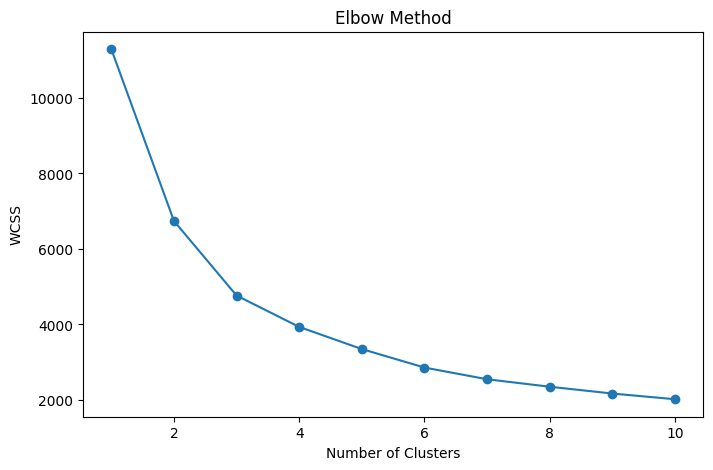

In [ ]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)

    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.show()

In [ ]:
# Select optimal number of clusters
k = 4

# Create K-Means model
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

# Fit the model
kmeans.fit(scaled_data)

# Add cluster labels
df['KMeans_Cluster'] = kmeans.labels_

print("K-Means Clustering Completed")

print(df[['SALES', 'QUANTITYORDERED', 'KMeans_Cluster']].head())

K-Means Clustering Completed
     SALES  QUANTITYORDERED  KMeans_Cluster
0  2871.00               30               1
1  2765.90               34               1
2  3884.34               41               0
3  3746.70               45               0
4  5205.27               49               2


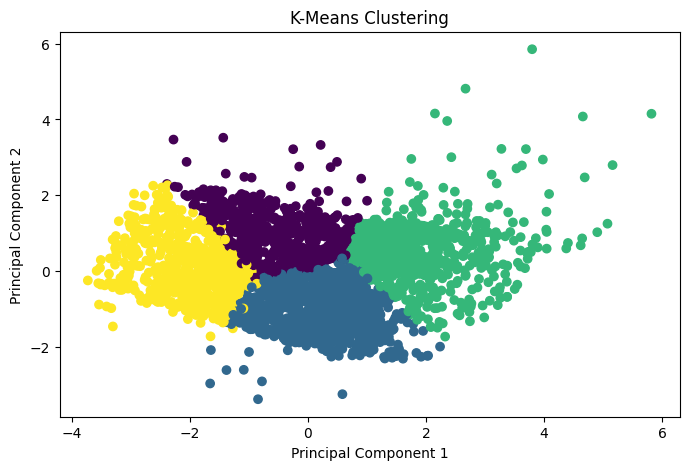

In [ ]:
# Reduce data to two dimensions
pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

# Plot clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=kmeans.labels_,
    cmap='viridis'
)

plt.title("K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [ ]:
# Create Hierarchical Clustering model
hc = AgglomerativeClustering(
    n_clusters=k,
    linkage='ward'
)

# Fit the model
hc_labels = hc.fit_predict(scaled_data)

# Add cluster labels
df['Hierarchical_Cluster'] = hc_labels

print("Hierarchical Clustering Completed")

print(df[['SALES', 'QUANTITYORDERED', 'Hierarchical_Cluster']].head())

Hierarchical Clustering Completed
     SALES  QUANTITYORDERED  Hierarchical_Cluster
0  2871.00               30                     2
1  2765.90               34                     2
2  3884.34               41                     3
3  3746.70               45                     3
4  5205.27               49                     0


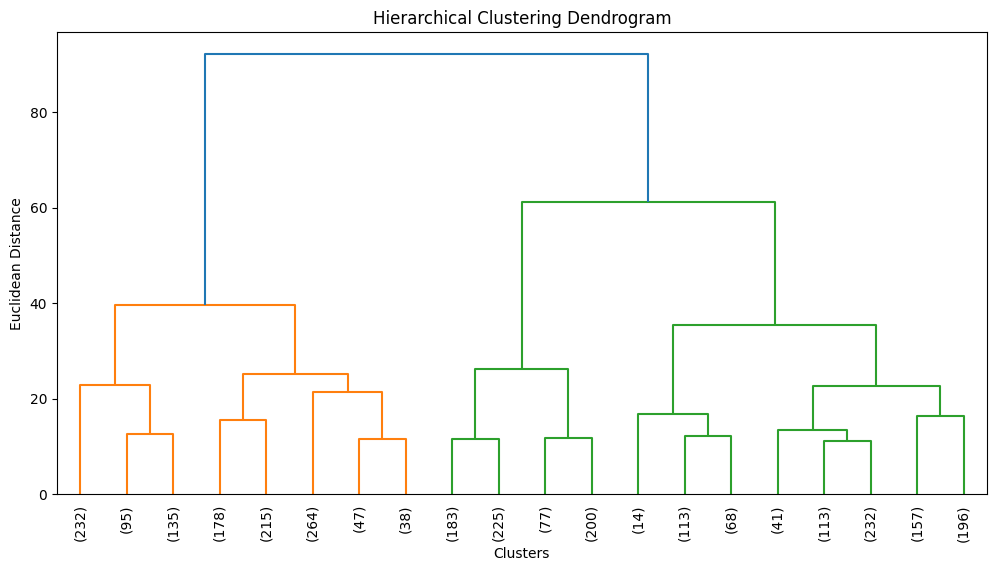

In [ ]:
# Create linkage matrix
linked = linkage(
    scaled_data,
    method='ward'
)

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=20,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Euclidean Distance")

plt.show()

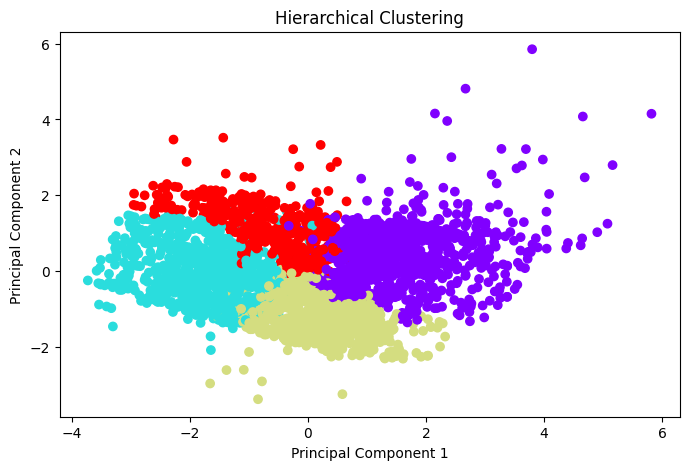

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=hc_labels,
    cmap='rainbow'
)

plt.title("Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [ ]:
# Compare cluster distribution
print("K-Means Cluster Distribution:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nHierarchical Cluster Distribution:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

K-Means Cluster Distribution:
KMeans_Cluster
0    561
1    930
2    705
3    627
Name: count, dtype: int64

Hierarchical Cluster Distribution:
Hierarchical_Cluster
0    934
1    742
2    685
3    462
Name: count, dtype: int64


In [ ]:
# K-Means cluster analysis
print("K-Means Cluster Analysis:")

print(
    df.groupby('KMeans_Cluster')[
        ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
    ].mean()
)

# Hierarchical cluster analysis
print("\nHierarchical Cluster Analysis:")

print(
    df.groupby('Hierarchical_Cluster')[
        ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
    ].mean()
)

K-Means Cluster Analysis:
                QUANTITYORDERED  PRICEEACH        SALES        MSRP
KMeans_Cluster                                                     
0                     43.720143  73.228271  3199.878717   75.982175
1                     27.353763  96.522602  3157.944968  114.732258
2                     43.228369  99.564468  6069.536525  135.974468
3                     29.704944  56.025582  1629.321882   62.409888

Hierarchical Cluster Analysis:
                      QUANTITYORDERED  PRICEEACH        SALES        MSRP
Hierarchical_Cluster                                                     
0                           41.710921  99.286777  5575.633972  127.048180
1                           30.129380  59.960593  1792.272938   70.299191
2                           25.389781  97.347737  3048.595547  117.837956
3                           44.071429  69.827403  3045.091450   70.943723


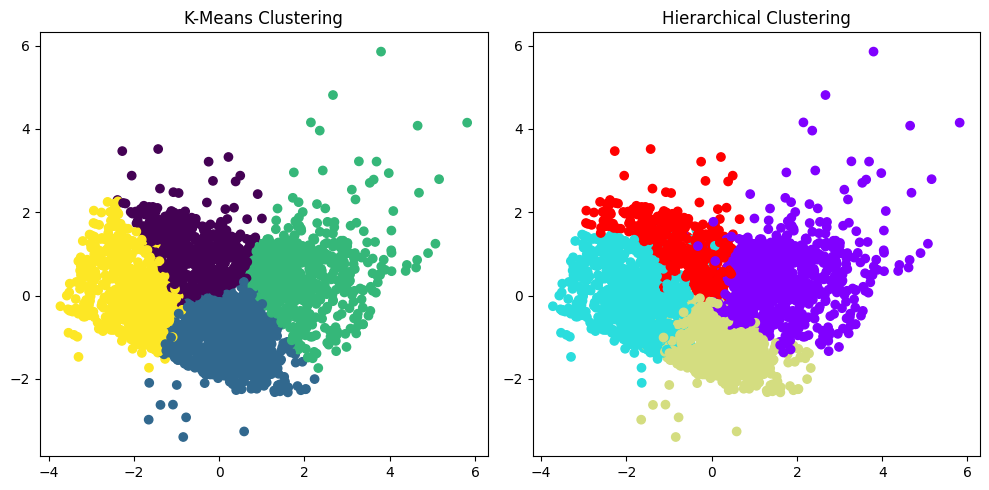

In [ ]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=kmeans.labels_,
    cmap='viridis'
)

plt.title("K-Means Clustering")

plt.subplot(1, 2, 2)

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=hc_labels,
    cmap='rainbow'
)

plt.title("Hierarchical Clustering")

plt.tight_layout()

plt.show()